# Softmax Regression from Scratch (NumPy): Digit Recognizer

> Part of [machine-learning-fundamentals](../README.md). Penjelasan di notebook ini ditulis dalam Bahasa Indonesia.

**Aturan:** inti Softmax Regression (softmax, cross-entropy, gradien, training, prediksi) ditulis **hanya dengan NumPy**. Matplotlib hanya untuk visualisasi. Scikit-Learn dan Pandas **tidak dipakai** di notebook ini (pembacaan CSV dan tabel hasil juga memakai NumPy).

**Reproducibility:** seluruh proses acak memakai `SEED = 42` (split, inisialisasi bobot, shuffle mini-batch).

## 0. Setup dan Konfigurasi

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

SEED = 42                      # seed global untuk reproducibility
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 110

DATA_PATH = "../data/digit-recognizer/train.csv"   # relatif terhadap folder notebook

## 1. Pra-pemrosesan Data
Langkah: (1) muat data, (2) pisahkan label dan piksel, (3) **normalisasi** piksel ke [0, 1] dengan membagi 255, (4) **flattening** — data Kaggle sudah berbentuk vektor 784 dimensi (28x28), jadi kita cek bentuknya dan hanya reshape saat visualisasi, (5) **one-hot encoding** label 0-9, (6) **train/test split** manual dengan seed yang jelas.

Catatan: `test.csv` Kaggle tidak berlabel, sehingga evaluasi (akurasi, confusion matrix) dilakukan pada split dari `train.csv`.

In [2]:
data = np.loadtxt(DATA_PATH, delimiter=",", skiprows=1)   # baris 1 = header
print("Bentuk data:", data.shape)

y_all = data[:, 0].astype(int)            # kolom 0 = label
X_all = data[:, 1:].astype(np.float64)    # kolom 1..784 = piksel
labels, counts = np.unique(y_all, return_counts=True)
print("Distribusi kelas:", dict(zip(labels.tolist(), counts.tolist())))

# Normalisasi [0, 1]
X_all = X_all / 255.0
print("Rentang piksel setelah normalisasi:", X_all.min(), "-", X_all.max())
print("Dimensi vektor fitur (flattened 28x28):", X_all.shape[1])

Bentuk data: (42000, 785)
Distribusi kelas: {0: 4132, 1: 4684, 2: 4177, 3: 4351, 4: 4072, 5: 3795, 6: 4137, 7: 4401, 8: 4063, 9: 4188}


Rentang piksel setelah normalisasi: 0.0 - 1.0
Dimensi vektor fitur (flattened 28x28): 784


In [3]:
def train_test_split_np(X, y, test_size=0.2, seed=SEED):
    # Split acak dengan seed tetap (NumPy murni).
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_size)
    test_idx, train_idx = idx[:n_test], idx[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]

def one_hot(y, num_classes=10):
    # Ubah label (N,) menjadi matriks one-hot (N, K).
    Y = np.zeros((len(y), num_classes))
    Y[np.arange(len(y)), y] = 1.0
    return Y

X_train, X_test, y_train, y_test = train_test_split_np(X_all, y_all, test_size=0.2, seed=SEED)
Y_train, Y_test = one_hot(y_train), one_hot(y_test)
print("Train:", X_train.shape, Y_train.shape, "| Test:", X_test.shape, Y_test.shape)

Train: (33600, 784) (33600, 10) | Test: (8400, 784) (8400, 10)


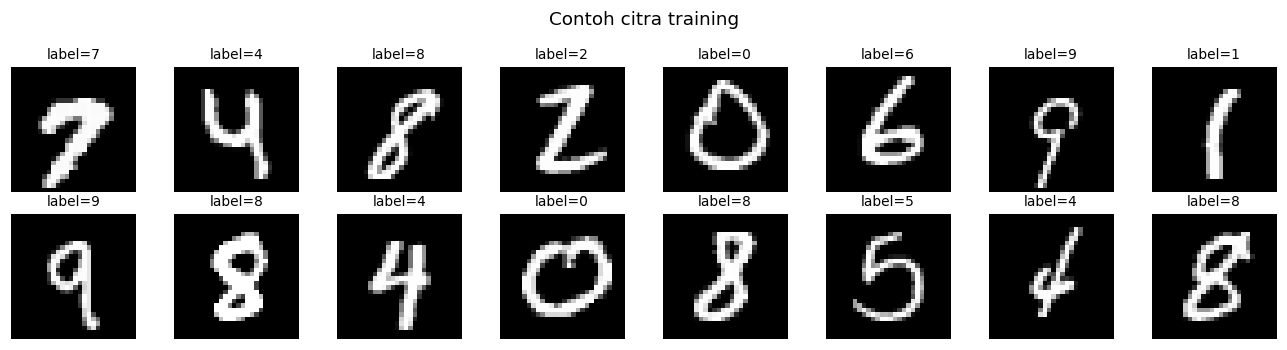

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.2))
for ax, i in zip(axes.ravel(), range(16)):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"label={y_train[i]}", fontsize=9); ax.axis("off")
plt.suptitle("Contoh citra training"); plt.tight_layout(); plt.show()

## 2. Fungsi Inti Softmax Regression
Untuk data $X \in \mathbb{R}^{N\times D}$, bobot $W \in \mathbb{R}^{D\times K}$, bias $b \in \mathbb{R}^{K}$:

- **Logit:** $Z = XW + b$
- **Softmax:** $P_{ik} = \dfrac{e^{Z_{ik}}}{\sum_j e^{Z_{ij}}}$ — dikurangi $\max_j Z_{ij}$ per baris agar stabil secara numerik (hasil tidak berubah karena softmax invarian terhadap pergeseran konstan).
- **Cross-entropy rata-rata (+ L2):** $L = -\dfrac{1}{N}\sum_i\sum_k Y_{ik}\log P_{ik} + \dfrac{\lambda}{2}\lVert W\rVert_F^2$
- **Gradien:** $\nabla_W L = \dfrac{1}{N}X^\top(P - Y) + \lambda W$, &nbsp; $\nabla_b L = \dfrac{1}{N}\sum_i (P_i - Y_i)$ (bias tidak diregularisasi)
- **Prediksi:** $\hat{y} = \arg\max_k \,\mathrm{Softmax}(XW + b)_k$

Mengapa gradiennya $(P-Y)$: turunan cross-entropy terhadap logit $Z$ untuk pasangan softmax + cross-entropy menyederhana menjadi $P - Y$.

In [5]:
def softmax(Z):
    # Probabilitas tiap kelas; stabil secara numerik.
    Z_shift = Z - Z.max(axis=1, keepdims=True)
    expZ = np.exp(Z_shift)
    return expZ / expZ.sum(axis=1, keepdims=True)

def cross_entropy_loss(P, Y, W=None, lam=0.0):
    # Loss cross-entropy rata-rata (+ penalti L2 bila lam > 0).
    eps = 1e-12
    loss = -np.mean(np.sum(Y * np.log(P + eps), axis=1))
    if lam > 0 and W is not None:
        loss += 0.5 * lam * np.sum(W ** 2)
    return loss

def compute_gradients(X, Y, P, W, lam=0.0):
    # Gradien loss terhadap W dan b.
    N = X.shape[0]
    diff = P - Y                       # (N, K)
    dW = X.T @ diff / N + lam * W      # (D, K)
    db = diff.mean(axis=0)             # (K,)
    return dW, db

def predict_proba(X, W, b):
    return softmax(X @ W + b)

def predict(X, W, b):
    # kelas = argmax(Softmax(XW + b))
    return np.argmax(predict_proba(X, W, b), axis=1)

def accuracy(y_true, y_pred):
    return float(np.mean(y_true == y_pred))

def train_softmax(X, Y, lr=0.1, epochs=50, batch_size=128, lam=0.0, seed=SEED,
                  X_val=None, y_val=None):
    # Mini-batch gradient descent. Mengembalikan W, b, dan riwayat loss/akurasi per epoch.
    rng = np.random.default_rng(seed)
    N, D = X.shape
    K = Y.shape[1]
    W = rng.normal(0.0, 0.01, size=(D, K))   # inisialisasi kecil dengan seed
    b = np.zeros(K)
    y_idx = Y.argmax(axis=1)
    hist = {"loss": [], "train_acc": [], "val_acc": []}
    for ep in range(epochs):
        order = rng.permutation(N)                    # shuffle tiap epoch
        for start in range(0, N, batch_size):
            batch = order[start:start + batch_size]
            Xb, Yb = X[batch], Y[batch]
            P = softmax(Xb @ W + b)
            dW, db = compute_gradients(Xb, Yb, P, W, lam)
            W -= lr * dW
            b -= lr * db
        P_full = softmax(X @ W + b)
        hist["loss"].append(cross_entropy_loss(P_full, Y, W, lam))
        hist["train_acc"].append(accuracy(y_idx, np.argmax(P_full, axis=1)))
        if X_val is not None:
            hist["val_acc"].append(accuracy(y_val, predict(X_val, W, b)))
    return W, b, hist

### Verifikasi gradien (gradient check)
Sebelum eksperimen, gradien analitik dibandingkan dengan gradien numerik (selisih terhingga) pada data kecil. Kalau implementasi benar, selisih relatifnya sangat kecil (di bawah $10^{-6}$).

In [6]:
def numerical_grad_W(X, Y, W, b, lam, h=1e-5, n_checks=8, seed=SEED):
    rng = np.random.default_rng(seed)
    coords = [(rng.integers(W.shape[0]), rng.integers(W.shape[1])) for _ in range(n_checks)]
    out = []
    for (i, k) in coords:
        W[i, k] += h;  lp = cross_entropy_loss(softmax(X @ W + b), Y, W, lam)
        W[i, k] -= 2*h; lm = cross_entropy_loss(softmax(X @ W + b), Y, W, lam)
        W[i, k] += h
        out.append(((i, k), (lp - lm) / (2 * h)))
    return out

rng = np.random.default_rng(SEED)
Xs, Ys = X_train[:50], Y_train[:50]
Ws, bs = rng.normal(0, 0.1, (784, 10)), np.zeros(10)
lam_chk = 0.01
dW_a, _ = compute_gradients(Xs, Ys, softmax(Xs @ Ws + bs), Ws, lam_chk)
errs = []
for (i, k), g_num in numerical_grad_W(Xs, Ys, Ws, bs, lam_chk):
    g_ana = dW_a[i, k]
    errs.append(abs(g_ana - g_num) / max(1e-12, abs(g_ana) + abs(g_num)))
print("Galat relatif maksimum gradien analitik vs numerik:", max(errs))

Galat relatif maksimum gradien analitik vs numerik: 4.490858649321505e-09


## 3. Eksperimen
Grid eksperimen penuh: learning rate $\alpha \in \{0.1, 0.01, 0.001\}$ x epoch $\in \{50, 100\}$ x L2 $\lambda \in \{0, 0.01\}$ = **12 konfigurasi**. Mini-batch = 128. Semua run memakai seed yang sama sehingga perbedaan hasil hanya berasal dari hiperparameter.

In [7]:
LRS, EPOCHS, LAMS = [0.1, 0.01, 0.001], [50, 100], [0.0, 0.01]
BATCH = 128
results, models = [], {}
t0 = time.time()
for lam in LAMS:
    for lr in LRS:
        for ep in EPOCHS:
            W, b, hist = train_softmax(X_train, Y_train, lr=lr, epochs=ep, batch_size=BATCH,
                                       lam=lam, seed=SEED, X_val=X_test, y_val=y_test)
            tr = accuracy(y_train, predict(X_train, W, b))
            te = accuracy(y_test, predict(X_test, W, b))
            key = (lr, ep, lam)
            models[key] = (W, b, hist)
            results.append({"learning_rate": lr, "epoch": ep, "lambda_L2": lam,
                            "train_acc": tr, "test_acc": te,
                            "gap": tr - te, "final_loss": hist["loss"][-1]})
            print(f"lr={lr:<6} epoch={ep:<4} lam={lam:<5} train={tr:.4f} test={te:.4f}")
print(f"Total waktu: {time.time()-t0:.1f} dtk")

lr=0.1    epoch=50   lam=0.0   train=0.9318 test=0.9200


lr=0.1    epoch=100  lam=0.0   train=0.9364 test=0.9225


lr=0.01   epoch=50   lam=0.0   train=0.9105 test=0.9039


lr=0.01   epoch=100  lam=0.0   train=0.9185 test=0.9118


lr=0.001  epoch=50   lam=0.0   train=0.8697 test=0.8625


lr=0.001  epoch=100  lam=0.0   train=0.8845 test=0.8781


... (2 outputs left out)

lr=0.01   epoch=50   lam=0.01  train=0.9029 test=0.8949


lr=0.01   epoch=100  lam=0.01  train=0.9050 test=0.8974


lr=0.001  epoch=50   lam=0.01  train=0.8689 test=0.8614


lr=0.001  epoch=100  lam=0.01  train=0.8833 test=0.8760
Total waktu: 231.1 dtk


In [8]:
# Tabel perbandingan (diurutkan menurut akurasi test)
ranked = sorted(results, key=lambda r: r["test_acc"], reverse=True)
header = f"{'No':>3} | {'lr':>6} | {'epoch':>5} | {'lambda':>6} | {'train (%)':>9} | {'test (%)':>8} | {'gap (%)':>7} | {'loss akhir':>10}"
print(header); print("-" * len(header))
for n, r in enumerate(ranked, 1):
    print(f"{n:>3} | {r['learning_rate']:>6} | {r['epoch']:>5} | {r['lambda_L2']:>6} | {r['train_acc']*100:>9.2f} | "
          f"{r['test_acc']*100:>8.2f} | {r['gap']*100:>7.2f} | {r['final_loss']:>10.4f}")

 No |     lr | epoch | lambda | train (%) | test (%) | gap (%) | loss akhir
---------------------------------------------------------------------------
  1 |    0.1 |   100 |    0.0 |     93.64 |    92.25 |    1.39 |     0.2304
  2 |    0.1 |    50 |    0.0 |     93.18 |    92.00 |    1.18 |     0.2453
  3 |   0.01 |   100 |    0.0 |     91.85 |    91.18 |    0.67 |     0.2923
  4 |   0.01 |    50 |    0.0 |     91.05 |    90.39 |    0.66 |     0.3226
  5 |    0.1 |   100 |   0.01 |     90.33 |    89.92 |    0.42 |     0.5378
  6 |    0.1 |    50 |   0.01 |     90.29 |    89.86 |    0.44 |     0.5377
  7 |   0.01 |   100 |   0.01 |     90.50 |    89.74 |    0.76 |     0.5399
  8 |   0.01 |    50 |   0.01 |     90.29 |    89.49 |    0.80 |     0.5435
  9 |  0.001 |   100 |    0.0 |     88.45 |    87.81 |    0.64 |     0.4482
 10 |  0.001 |   100 |   0.01 |     88.33 |    87.60 |    0.73 |     0.5803
 11 |  0.001 |    50 |    0.0 |     86.97 |    86.25 |    0.72 |     0.5500
 12 |  0.001

## 4. Analisis Hasil
### 4.1 Plot Loss vs Epoch (overlay)

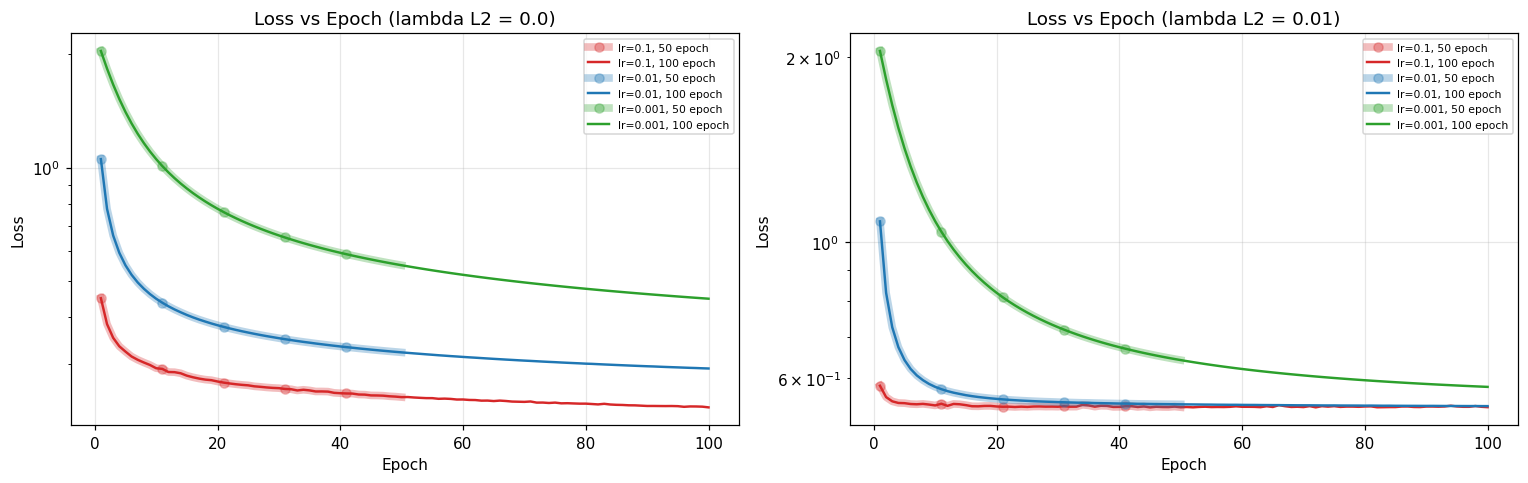

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)
cmap = {0.1: "tab:red", 0.01: "tab:blue", 0.001: "tab:green"}
for ax, lam in zip(axes, LAMS):
    for lr in LRS:
        for ep in EPOCHS:
            hist = models[(lr, ep, lam)][2]
            if ep == 100:
                ax.plot(range(1, ep + 1), hist["loss"], color=cmap[lr], lw=1.6, label=f"lr={lr}, {ep} epoch")
            else:   # garis 50 epoch: tebal + transparan + marker agar terlihat di bawah garis 100 epoch
                ax.plot(range(1, ep + 1), hist["loss"], color=cmap[lr], lw=5, alpha=.3,
                        marker="o", markevery=10, ms=6, label=f"lr={lr}, {ep} epoch")
    ax.set_title(f"Loss vs Epoch (lambda L2 = {lam})")
    ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.set_yscale("log"); ax.grid(alpha=.3)
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

**Catatan membaca grafik:** semua run memakai seed yang sama, sehingga urutan mini-batch pada 50 epoch pertama identik. Akibatnya kurva 50 epoch (garis tebal transparan bermarker) **berimpit tepat** dengan separuh pertama kurva 100 epoch. Run 100 epoch adalah kelanjutan run 50 epoch, dan selisih akurasinya murni efek 50 epoch tambahan.

### 4.2 Eksperimen terbaik dan Confusion Matrix

Konfigurasi terbaik: (0.1, 100, 0.0) | train=0.9364 test=0.9225


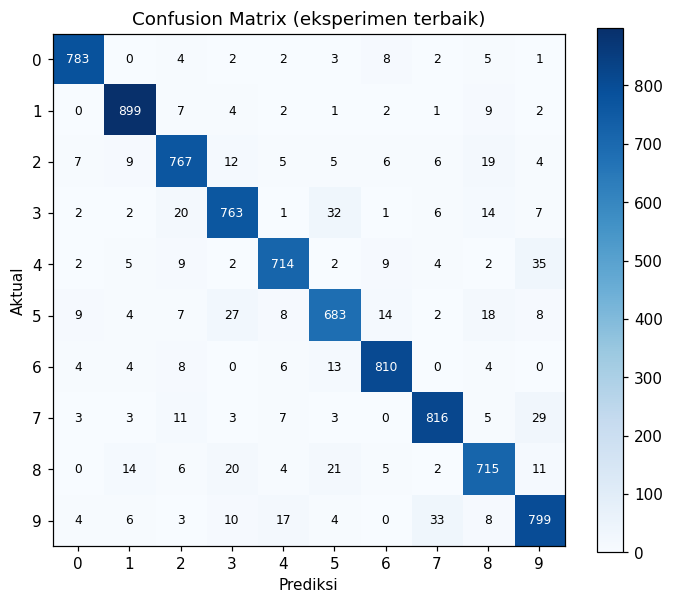

In [10]:
best = max(results, key=lambda r: r["test_acc"])
best_key = (best["learning_rate"], best["epoch"], best["lambda_L2"])
print("Konfigurasi terbaik:", best_key, f"| train={best['train_acc']:.4f} test={best['test_acc']:.4f}")
Wb, bb, _ = models[best_key]

def confusion_matrix_np(y_true, y_pred, K=10):
    cm = np.zeros((K, K), dtype=int)
    np.add.at(cm, (y_true, y_pred), 1)
    return cm

y_pred = predict(X_test, Wb, bb)
cm = confusion_matrix_np(y_test, y_pred)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("Prediksi"); ax.set_ylabel("Aktual"); ax.set_title("Confusion Matrix (eksperimen terbaik)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im); plt.tight_layout(); plt.show()

### 4.3 Visualisasi Bobot W sebagai template per kelas
Setiap kolom $W_{:,k}$ (784 nilai) di-reshape menjadi 28x28. Piksel merah/positif menaikkan skor kelas $k$ jika menyala, piksel biru/negatif menurunkannya.

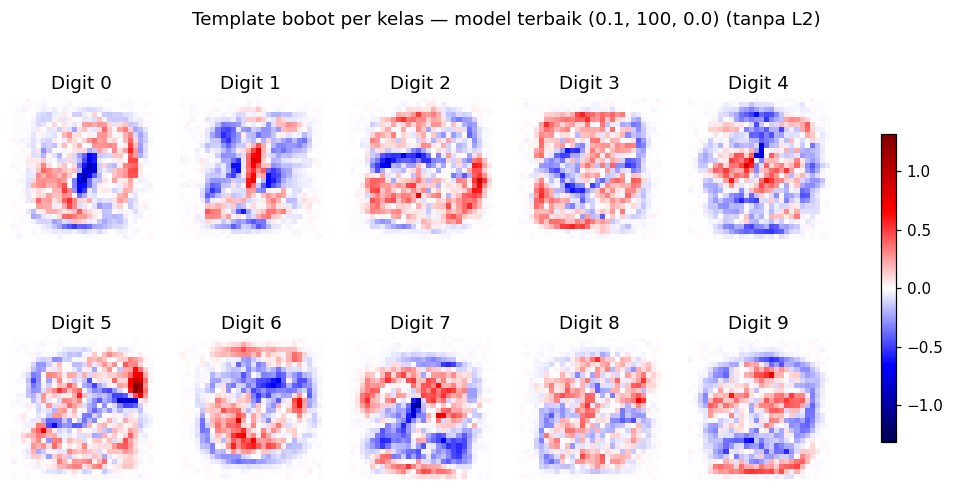

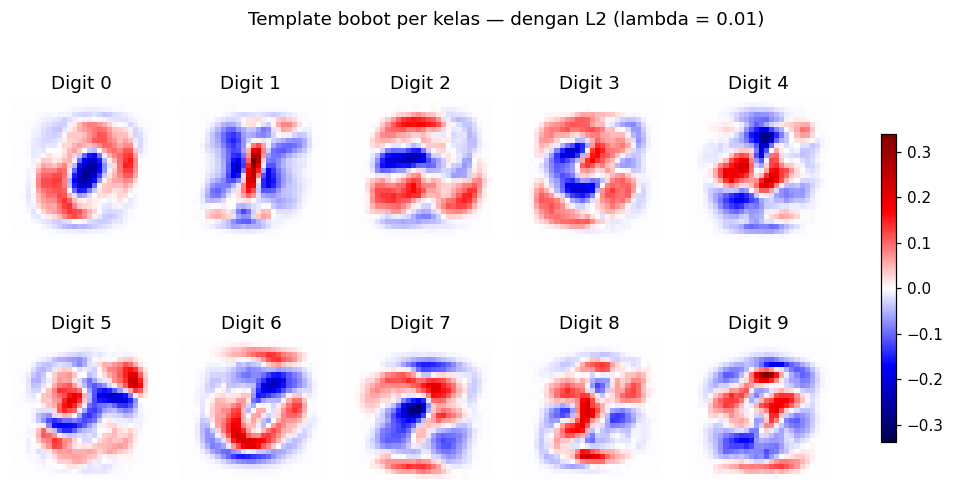

Norma ||W|| tanpa L2: 17.36 | dengan L2: 5.44


In [11]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
vmax = np.abs(Wb).max()
for k, ax in enumerate(axes.ravel()):
    im = ax.imshow(Wb[:, k].reshape(28, 28), cmap="seismic", vmin=-vmax, vmax=vmax)
    ax.set_title(f"Digit {k}"); ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.7)
plt.suptitle(f"Template bobot per kelas — model terbaik {best_key} (tanpa L2)"); plt.show()

# Pembanding: model dengan L2 (lr dan epoch sama) -> template lebih halus
W_l2 = models[(best_key[0], best_key[1], 0.01)][0]
fig, axes = plt.subplots(2, 5, figsize=(12, 5.2))
vmax = np.abs(W_l2).max()
for k, ax in enumerate(axes.ravel()):
    im = ax.imshow(W_l2[:, k].reshape(28, 28), cmap="seismic", vmin=-vmax, vmax=vmax)
    ax.set_title(f"Digit {k}"); ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.7)
plt.suptitle(f"Template bobot per kelas — dengan L2 (lambda = 0.01)"); plt.show()
print("Norma ||W|| tanpa L2: %.2f | dengan L2: %.2f" % (np.linalg.norm(Wb), np.linalg.norm(W_l2)))

**Interpretasi template.** Pada model tanpa L2, template tampak "berbintik" karena bobot bebas membesar untuk menghafal detail piksel tertentu (termasuk piksel tepi yang jarang menyala). Dengan L2, bobot ditekan sehingga template lebih halus dan bentuk digit (lingkaran 0, garis tegak 1, dsb.) lebih jelas terlihat. Template yang lebih halus lebih mudah ditafsirkan, tetapi pada data ini akurasinya lebih rendah, karena lambda = 0.01 terlalu kuat (lihat tabel).

### 4.4 Digit yang paling sering salah diklasifikasikan

In [12]:
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
per_class_acc = np.diag(cm) / cm.sum(axis=1)
err_rate = 1 - per_class_acc
print("Akurasi per digit:")
for k in range(10):
    print(f"  {k}: {per_class_acc[k]:.4f}")

pairs = [(cm_off[i, j], i, j) for i in range(10) for j in range(10) if i != j]
pairs.sort(reverse=True)
print("\nPasangan salah terbanyak (aktual -> prediksi):")
for n, i, j in pairs[:6]:
    print(f"  {i} -> {j}: {n} sampel")
print("\nDigit paling sulit:", int(np.argmax(err_rate)), f"(error {err_rate.max():.2%})")

Akurasi per digit:
  0: 0.9667
  1: 0.9698
  2: 0.9131
  3: 0.8998
  4: 0.9107
  5: 0.8756
  6: 0.9541
  7: 0.9273
  8: 0.8960
  9: 0.9038

Pasangan salah terbanyak (aktual -> prediksi):
  4 -> 9: 35 sampel
  9 -> 7: 33 sampel
  3 -> 5: 32 sampel
  7 -> 9: 29 sampel
  5 -> 3: 27 sampel
  8 -> 5: 21 sampel

Digit paling sulit: 5 (error 12.44%)


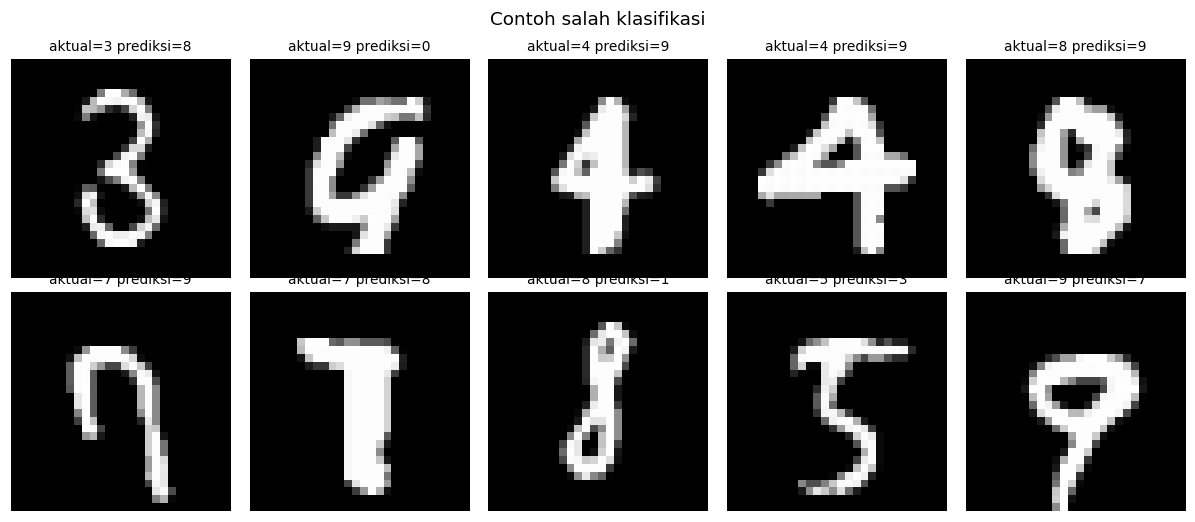

In [13]:
wrong = np.where(y_test != y_pred)[0]
rng = np.random.default_rng(SEED)
show = rng.choice(wrong, size=10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(11, 4.8))
for ax, i in zip(axes.ravel(), show):
    ax.imshow(X_test[i].reshape(28, 28), cmap="gray")
    ax.set_title(f"aktual={y_test[i]} prediksi={y_pred[i]}", fontsize=9); ax.axis("off")
plt.suptitle("Contoh salah klasifikasi"); plt.tight_layout(); plt.show()

### 4.5 Kesimpulan dan Interpretasi

- **Hasil terbaik:** lr = 0.1, 100 epoch, tanpa L2 → akurasi train **93.64%**, test **92.25%**. Gradient check menghasilkan galat relatif sekitar 4.5e-9, jadi gradien analitik terbukti benar.
- **Learning rate:** semakin kecil lr, semakin lambat konvergensi. Tanpa L2 pada 100 epoch, test = 92.25% (lr 0.1), 91.18% (lr 0.01), dan 87.81% (lr 0.001). lr 0.001 jelas belum konvergen dalam 100 epoch.
- **Jumlah epoch:** menambah epoch dari 50 ke 100 selalu menaikkan akurasi, paling besar pada lr kecil (lr 0.01: 90.39% → 91.18%; lr 0.1: 92.00% → 92.25%). Kurva loss pada lr 0.1 sudah melandai.
- **L2 (lambda = 0.01):** menurunkan akurasi test pada lr 0.1 dari 92.25% ke 89.92% dan pada lr 0.01 dari 91.18% ke 89.74%. Kesenjangan train-test model tanpa L2 hanya sekitar 1.4 poin, jadi hampir tidak ada overfitting yang perlu diredam; lambda 0.01 terlalu kuat dan justru menyebabkan underfitting (bobot terlalu ditekan, loss akhir juga lebih tinggi karena memuat suku penalti). Nilai lambda yang lebih kecil (misal 1e-4 atau 1e-3) layak dicoba.
- **Kesalahan terbanyak:** pasangan 4→9 (35), 9→7 (33), 3→5 (32), 7→9 (29), 5→3 (27). Digit paling sulit adalah **5** (error 12.44%), diikuti 8 dan 3. Penyebabnya: model linear hanya memiliki satu template per kelas, sehingga digit yang bentuknya mirip (4/9/7, 3/5/8) dan gaya tulisan yang bervariasi tidak bisa dipisahkan dengan batas linear. Template bobot per kelas memperlihatkan bentuk rata-rata digit, bukan variasinya.
- **Keterbatasan:** softmax linear pada piksel mentah mentok di sekitar 92-93%. Model nonlinear (MLP/CNN) diperlukan untuk akurasi lebih tinggi.

## 5. Submission ke Kaggle (Bonus)
Konfigurasi terbaik dari eksperimen dilatih ulang pada **seluruh 42.000 data latih** (train + test split), lalu memprediksi 28.000 citra pada `test.csv` Kaggle. Hiperparameter tidak diubah, sehingga tidak ada pemilihan yang didasarkan pada data test Kaggle. Pra-pemrosesan sama: bagi 255 dan vektor 784 dimensi. Seluruhnya tetap memakai NumPy.

In [14]:
lr_b, ep_b, lam_b = best_key
Y_all = one_hot(y_all)
W_final, b_final, hist_final = train_softmax(X_all, Y_all, lr=lr_b, epochs=ep_b, batch_size=BATCH, lam=lam_b, seed=SEED)
print(f"Model final {best_key} | akurasi pada seluruh data latih: {accuracy(y_all, predict(X_all, W_final, b_final)):.4f}")

X_kaggle = np.loadtxt("../data/digit-recognizer/test.csv", delimiter=",", skiprows=1) / 255.0
print("Test Kaggle:", X_kaggle.shape)
pred_kaggle = predict(X_kaggle, W_final, b_final)

image_id = np.arange(1, len(pred_kaggle) + 1)
np.savetxt("submission_digit.csv", np.c_[image_id, pred_kaggle], fmt="%d", delimiter=",", header="ImageId,Label", comments="")
labels, counts = np.unique(pred_kaggle, return_counts=True)
print("submission_digit.csv tersimpan | distribusi prediksi:", dict(zip(labels.tolist(), counts.tolist())))

Model final (0.1, 100, 0.0) | akurasi pada seluruh data latih: 0.9348


Test Kaggle: (28000, 784)
submission_digit.csv tersimpan | distribusi prediksi: {0: 2798, 1: 3272, 2: 2762, 3: 2812, 4: 2772, 5: 2476, 6: 2775, 7: 2886, 8: 2676, 9: 2771}


File `submission_digit.csv` (kolom `ImageId,Label`, 28.000 baris) diunggah lewat tombol **Submit Prediction** di halaman kompetisi Digit Recognizer. Metrik kompetisi adalah accuracy. Skornya diperkirakan mendekati akurasi test split (sekitar 92%), karena model linear ini hanya sedikit overfit.

## 6. Referensi

| No | Sumber / Tool | Tujuan Penggunaan | Link / Keterangan |
|----|---------------|-------------------|-------------------|
| 1 | Kaggle — Digit Recognizer | Sumber dataset | https://www.kaggle.com/competitions/digit-recognizer |
| 2 | NumPy & Matplotlib documentation | Memahami API array dan plotting | https://numpy.org/doc , https://matplotlib.org |